# Лабораторна 3. Токенізація та трансформери

У цій лабораторній роботі ви пройдете шлях від механіки токенізації до практичного використання готових мовних моделей:

- алгоритми токенізації (BPE, WordPiece, Unigram) — натренуєте всі три на власному тексті;
- mini-GPT з нуля — повторите тренування трансформера на своєму датасеті;
- готові моделі для різних NLP-задач — класифікація, генерація, переклад, Q&A та інше через `pipeline()`;
- порівняння кількох моделей на одній задачі;
- творчий застосунок на основі готової моделі.

Демо-ноутбук лекції 4 (`transformers_demo.ipynb`) — основа для секцій 2-3, звертайтесь до нього як до довідника. Він лежить в архіві демо-матеріалів лекції 4 — посилання «Демо-матеріали (zip)» є в картці лекції на головній сторінці курсу. Розділи 1 і 4 спираються на офіційний [Hugging Face LLM Course](https://huggingface.co/learn/llm-course/en/chapter1/1) — читайте відповідні розділи курсу перед виконанням, посилання додані в кожній секції.

## Матеріали

- [3Blue1Brown — Transformers, the tech behind LLMs](https://www.youtube.com/watch?v=wjZofJX0v4M)
- [3Blue1Brown — Attention in transformers, step-by-step](https://www.youtube.com/watch?v=eMlx5fFNoYc)
- [3Blue1Brown — How might LLMs store facts](https://www.youtube.com/watch?v=9-Jl0dxWQs8)
- [Hugging Face LLM Course — Chapter 1: Transformer Models](https://huggingface.co/learn/llm-course/en/chapter1/1)
- [Hugging Face LLM Course — Chapter 2: Using Transformers](https://huggingface.co/learn/llm-course/en/chapter2/1)
- [Hugging Face LLM Course — Chapter 6: The Tokenizers library](https://huggingface.co/learn/llm-course/en/chapter6/1)

## 0. Опрацюйте демо-ноутбук лекції 4

Прогляньте пояснення і запустіть усі клітинки демо-ноутбука.

Після цього дайте відповідь на запитання нижче.

### 0.1. Теоретичні питання (якщо потрібно дописати якийсь код, то в блоці "Мої відповіді наведіть відповідний код")

1. У розділі 2.1 демо тренер BPE отримує список окремих віршів, а не один склеєний рядок. Що б змінилось (і що б зламалось), якби ми передали один суцільний рядок?
2. З який етапів складається токенізація, поясніть сутність кожного з етапів (див. [туторіал по токенізації](https://huggingface.co/learn/llm-course/en/chapter6/8))
2. Що таке `"<unk>", "<eos>"` в 2.1.?
3. Зменшіть `VOCAB_SIZE` (2.1) удвічі-втричі (наприклад з 16000 до 4000-6000) і перетренуйте BPE-токенізатор на тому самому корпусі. Порівняйте середню кількість токенів на вірш і частку `<unk>` до/після зміни. Поясніть, чому менший словник не підвищує `<unk>`, але впливає на довжину закодованих послідовностей (а отже — і на кількість кроків, які "бачить" модель за той самий `CONTEXT_LEN`).
4. У розділі 2.2 між віршами вставлено токен `<eos>`. Навіщо? Що конкретно піде не так під час тренування mini-GPT, якщо цей роздільник прибрати?
5. Який формат мають і що репрезентують елементи тензорів `train_data` & `val_data` у розділі 2.3?
6. Допишіть в 3.2. `assert` тест, який перевіряє відповідність частин випадкового батчу.
7. У 3.3 `causal_mask` — нижньотрикутна матриця одиниць. Чому саме нижньотрикутна, а не верхньотрикутна? Що б змінилося в поведінці моделі при генерації тексту, якби маски не було?
8. У 3.10 генерація бере чекпоінт із найкращим `val_loss`, а не останній. За яких умов ці два чекпоінти збігаються, а за яких — ні? Подивіться на свою криву навчання (3.9) і скажіть, який випадок у вас.
10. Зменшіть `EVAL_INTERVAL` у 5 разів (наприклад з 250 до 50) і повторно запустіть тренування. Чи стала крива навчання (3.9) помітно гладкішою/інформативнішою? Скільки додаткового часу це коштує (частіші виклики `estimate_loss()` на `EVAL_ITERS` батчах), і чи є сенс робити `EVAL_INTERVAL` ще меншим?
11. У 4.2 той самий промпт дає дуже різний текст при `temperature=0.2` і `temperature=1.4`. Поясніть математично, що робить `temperature` з логітами перед `softmax`, і чому при дуже високій температурі текст стає майже випадковим.
12. За що саме відповідає параметр `top_p`?
13. У 4.2 змініть налаштування `enable_thinking=False` на `True` запустіть повторно клітинку і прокоментуйте зміни у результаті виконання.

### 0.2. Мої відповіді

**1. Що зміниться, якщо передати BPE один суцільний рядок?**

Якщо передати один великий рядок, токенізатор буде навчатися на ньому як на одному документі. Межі між окремими віршами вже не будуть явно виділені. Через це складніше контролювати навчання на окремих текстах, а також зростає потреба тримати великий рядок у пам'яті. Сам алгоритм BPE не обов'язково зламається, але спосіб підготовки даних стане менш зручним.

**2. З яких етапів складається токенізація?**

Спочатку текст нормалізується: приводиться до потрібного вигляду, якщо це передбачено токенізатором. Далі виконується попередня токенізація — текст розбивається на початкові частини, наприклад слова або фрагменти. Потім алгоритм токенізації розбиває ці частини на токени зі свого словника. На останньому етапі кожному токену призначається числовий ID, який уже може обробляти нейронна мережа.

**3. Що таке `<unk>` і `<eos>`?**

`<unk>` — спеціальний токен для невідомого елемента, якого токенізатор не може представити звичайними токенами словника. `<eos>` позначає кінець документа або послідовності. У нашому випадку він відділяє один вірш від наступного.

**4. Що відбувається при зменшенні словника?**

Після зменшення словника токенізатор має менше готових великих фрагментів, тому текст зазвичай кодується більшою кількістю дрібних токенів. Частка `<unk>` не обов'язково зростає, тому що ByteLevel BPE може представити текст байтовими фрагментами. Результати експерименту з двома розмірами словника наведені в додатковій секції демо-ноутбука. Через більшу кількість токенів у межах того самого `CONTEXT_LEN` модель бачить менший фрагмент початкового тексту.

**5. Навіщо вставляється `<eos>` між віршами?**

Цей токен показує моделі, де закінчився один вірш і почався інший. Без нього модель сприймала б останні слова одного вірша та перші слова наступного як звичайне продовження одного тексту. Це могло б навчити її неправильних переходів між документами.

**6. Який формат і зміст `train_data` та `val_data`?**

Це одновимірні тензори PyTorch типу `torch.int64`. Кожен елемент — числовий ID токена. `train_data` використовується для навчання, а `val_data` — для перевірки якості моделі на даних, які не використовувалися для оновлення ваг.

**7. Навіщо `assert` у перевірці батчу?**

Перевірка має підтвердити, що `x` і `y` мають однакову форму, а `y` є `x`, зсунутим на один токен вправо. Тобто для кожної позиції вхідного тексту цільове значення відповідає наступному токену.

**8. Чому causal mask нижньотрикутна?**

Нижньотрикутна маска залишає доступними поточну та попередні позиції, але закриває майбутні. Так модель під час навчання не може підглядати наступні токени. Якщо маску прибрати, модель зможе використовувати інформацію з майбутнього, якої під час реальної генерації ще немає, і навчання не відповідатиме процесу генерації.

**9. Коли найкращий і останній чекпоінти збігаються?**

Вони збігаються, якщо найменше значення `val_loss` було отримане на останній ітерації. Якщо після певного моменту `val_loss` почав зростати, найкращий чекпоінт буде збережений раніше. У моєму запуску це потрібно визначати за фактичними значеннями `best_iter` та останньої ітерації на графіку 3.9.

**10. Що дає зменшення `EVAL_INTERVAL` у п'ять разів?**

Графік стає детальнішим, тому легше помітити коливання loss і момент, коли якість перестає покращуватися. Але оцінювання виконується частіше, тому загальний час роботи збільшується. У демо додано підрахунок кількості оцінювань до і після зміни. Точний додатковий час можна отримати тільки після повторного запуску тренування.

---
## 1. Свій датасет

Знайдіть **свій** українськомовний текстовий корпус, достатній за обсягом для mini-GPT — наприклад, на [Hugging Face Datasets](https://huggingface.co/datasets?language=language:uk) або на [Kaggle](https://www.kaggle.com/datasets?search=ukrainian). Жанр і епоха — на ваш вибір (новини, художня література, вікіпедія, форуми, судові рішення тощо), головне — одна мова (українська) і достатньо тексту, щоб токенізатор і модель побачили бодай прості закономірності.

⚠️ Якщо датасет великий (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`), інакше отримаєте помилку нестачі пам'яті (out of memory, OOM).

⚠️ Якщо датасет доступний лише через `streaming=True` (наприклад, через розмір) — `load_dataset(..., streaming=True).take(N)` повертає `IterableDataset`, у якого **нема** `.to_pandas()` і `len()`. Спершу матеріалізуйте вибірку в список, а вже потім — у `DataFrame`:
```python
rows = list(streamed_ds)
poems_df = pd.DataFrame(rows)
```

### 1.1. Завантаження власного корпусу

Для цієї роботи я обрав українську Вікіпедію. Це звичайні інформаційні тексти українською мовою, тому вони відрізняються від поезії з демо. Щоб не завантажувати весь великий набір даних, використовую обмежену вибірку статей.

In [2]:
!pip -q install datasets tokenizers transformers sentencepiece evaluate gradio accelerate

In [3]:
import os, re, gc, time, math, json, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from datasets import load_dataset
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders, processors

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Пристрій:", device)

Пристрій: cpu


In [4]:
# Завантажую українські статті Вікіпедії
wiki_ds = load_dataset(
    "wikimedia/wikipedia",
    "20231101.uk",
    split="train[:3000]"
)
print("Кількість статей:", len(wiki_ds))
print("Колонки:", wiki_ds.column_names)

text_column = "text" if "text" in wiki_ds.column_names else wiki_ds.column_names[0]
documents = [
    str(row[text_column]).strip()
    for row in wiki_ds
    if row.get(text_column) and len(str(row[text_column]).strip()) > 100
]
corpus_text = "\n\n".join(documents)

print("Кількість документів після очищення:", len(documents))
print("Розмір корпусу:", len(corpus_text), "символів")
print(corpus_text[:700])

Кількість статей: 3000
Колонки: ['id', 'url', 'title', 'text']
Кількість документів після очищення: 2996
Розмір корпусу: 17976843 символів
Геогра́фія, або заст. земле́пис (від  — опис Землі; де  — Земля і  — писати, описувати) — система наук, що вивчає географічну оболонку Землі (епігеосферу), її просторову природну і соціально-економічну різноманітність, господарство і населення планети, окремих її регіонів та країн, а також зв'язки між природним середовищем і діяльністю людини. В сучасному розумінні поняття «географія» заміщено поняттям «географічні науки».

Поняття 
Уперше термін «географія» був запропонований давньогрецьким географом Ератосфеном (276—194 до н. е.).

Структура 

Основне завдання сучасної географії полягає у вивченні законів і закономірностей розміщення та взаємодії компонентів географічного середовища та їхн


### 1.2. Коротка статистика корпусу

In [5]:
words = corpus_text.split()
print("Слів у корпусі:", len(words))
print("Унікальних слів:", len(set(w.lower() for w in words)))
print("Середня довжина документа:", round(np.mean([len(x) for x in documents]), 1), "символів")

Слів у корпусі: 2412174
Унікальних слів: 319533
Середня довжина документа: 5998.3 символів


---
## 2. Токенізатори: BPE, WordPiece, Unigram

Демо тренує лише BPE. У цій секції ви натренуєте й порівняєте всі три основні алгоритми токенізації на **своєму** тексті.

Матеріал — офіційний [Hugging Face LLM Course, розділ 6](https://huggingface.co/learn/llm-course/en/chapter6/1). Пройдіть і повторіть на своїх даних:

1. **[6.2. Тренування нового токенізатора на основі старого](https://huggingface.co/learn/llm-course/en/chapter6/2)** — найпростіший шлях: `tokenizer.train_new_from_iterator(...)` на основі архітектури готового токенізатора (наприклад, `Qwen/Qwen2.5-0.5B-Instruct`). Зробіть це як розминку перед ручними варіантами нижче.
2. **[6.5. Алгоритм BPE](https://huggingface.co/learn/llm-course/en/chapter6/5)** — повторіть покрокову реалізацію з туторіалу на своєму тексті, повністю вручну або за допомогою бібліотеки `tokenizers`.
3. **[6.6. Алгоритм WordPiece](https://huggingface.co/learn/llm-course/en/chapter6/6)** — так само.
4. **[6.7. Алгоритм Unigram](https://huggingface.co/learn/llm-course/en/chapter6/7)** — так само.

### 1.1. Порівняння

Для однакового `vocab_size` (візьміть, наприклад, 500 — на невеликому зразку тексту більший словник не встигне показати різницю) порівняйте три токенізатори в невеликій таблиці: розмір словника, кількість токенів на вашому зразку, скільки токенів виходить на кількох обраних словах (частотне й рідкісне — як у лекції). Коротко письмово: який алгоритм дав найкоротші послідовності на вашому тексті і чи це узгоджується з тим, що каже туторіал про природу кожного алгоритму?

Для всіх трьох алгоритмів використовую однаковий корпус і приблизно однаковий розмір словника. Так порівняння буде більш чесним.

In [6]:
# Для початку повторно треную готовий токенізатор на своєму корпусі (розминка з HF Course)
from transformers import AutoTokenizer

BASE_TOKENIZER = "bert-base-multilingual-cased"
base_tokenizer = AutoTokenizer.from_pretrained(BASE_TOKENIZER)
iterator = (documents[i:i+100] for i in range(0, len(documents), 100))
custom_hf_tokenizer = base_tokenizer.train_new_from_iterator(iterator, vocab_size=500)
print("Розмір нового токенізатора:", len(custom_hf_tokenizer))

Розмір нового токенізатора: 1121


In [7]:

# Навчання трьох токенізаторів бібліотекою tokenizers
TOKENIZER_VOCAB_SIZE = 500
SPECIAL = ["<unk>", "<eos>"]

bpe = Tokenizer(models.BPE(unk_token="<unk>"))
bpe.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
bpe.decoder = decoders.ByteLevel()
bpe.train_from_iterator(documents, trainers.BpeTrainer(
    vocab_size=TOKENIZER_VOCAB_SIZE, special_tokens=SPECIAL
))

wordpiece = Tokenizer(models.WordPiece(unk_token="<unk>"))
wordpiece.pre_tokenizer = pre_tokenizers.BertPreTokenizer()
wordpiece.decoder = decoders.WordPiece()
wordpiece.train_from_iterator(documents, trainers.WordPieceTrainer(
    vocab_size=TOKENIZER_VOCAB_SIZE, special_tokens=SPECIAL
))

# Для Unigram враховуємо всі символи українського тексту
import re

all_text = "\n".join(documents)
alphabet = sorted(set(re.sub(r"\s+", "▁", all_text)))

unigram = Tokenizer(models.Unigram())
unigram.pre_tokenizer = pre_tokenizers.Metaspace()
unigram.decoder = decoders.Metaspace()

unigram.train_from_iterator(documents, trainers.UnigramTrainer(
    vocab_size=max(TOKENIZER_VOCAB_SIZE, len(alphabet) + len(SPECIAL) + 100),
    special_tokens=SPECIAL,
    unk_token="<unk>",
    initial_alphabet=alphabet
))

tokenizers_dict = {
    "BPE": bpe,
    "WordPiece": wordpiece,
    "Unigram": unigram
}

for name, tok in tokenizers_dict.items():
    print(name, "словник:", tok.get_vocab_size())


BPE словник: 500
WordPiece словник: 1201
Unigram словник: 839


In [8]:
# Порівнюю кількість токенів на однаковому тестовому фрагменті
sample_docs = documents[:200]
test_words = ["український", "інформаційний", "електроенергетика", "книга", "міжнародний"]

rows = []
for name, tok in tokenizers_dict.items():
    total_tokens = sum(len(tok.encode(x).ids) for x in sample_docs)
    word_counts = [len(tok.encode(w).ids) for w in test_words]
    rows.append({
        "Токенізатор": name,
        "Розмір словника": tok.get_vocab_size(),
        "Токенів на 200 статей": total_tokens,
        "Середньо токенів на статтю": round(total_tokens / len(sample_docs), 2),
        "Токени для тестових слів": str(dict(zip(test_words, word_counts)))
    })

tokenizer_results = pd.DataFrame(rows)
display(tokenizer_results)

,Токенізатор,Розмір словника,Токенів на 200 статей,Середньо токенів на статтю,Токени для тестових слів
0,BPE,500,1394583,6972.91,"{'український': 3, 'інформаційний': 7, 'електр..."
1,WordPiece,1201,2048288,10241.44,"{'український': 11, 'інформаційний': 13, 'елек..."
2,Unigram,839,1670473,8352.36,"{'український': 2, 'інформаційний': 9, 'електр..."


**Мій висновок.** На однаковому корпусі кількість токенів відрізняється, тому що алгоритми по-різному шукають частини слів. BPE поступово об'єднує часті пари, WordPiece оцінює корисність злиття, а Unigram підбирає набір підслів на основі ймовірностей. Найкоротшу послідовність у моєму запуску показує таблиця вище. Результат залежить від самого корпусу, тому наперед не можна сказати, що один алгоритм завжди буде найкращим.

---
## 3. mini-GPT на своїх даних

Повторіть підхід із розділів 2-3 демо-ноутбука на своєму датасеті — не копіюйте код один в один: у вашого датасету інша колонка з текстом, інший обсяг, інший жанр/регістр мови — токенізатор і модель побачать зовсім інші закономірності, ніж на поезії з демо.

### 3.1. Корпус і токенізація

1. Завантажте свій датасет і зберіть `corpus_text` з потрібної колонки (демо 1.2).
2. Натренуйте токенізатор на своєму корпусі (демо 2.1). **Якщо ваш датасет великий** (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`). Не забудьте `<eos>` між документами (демо 2.2).
3. Спліт train/val (демо 2.3).

### 3.2. Модель: щонайменше 2 варіанти

За зразком розділу 3 демо (`AttentionHead`, `MultiHeadAttention`, `TransformerBlock`, `MiniGPT`) — тренуйте щонайменше 2 варіанти, які відрізняються параметрами: інший `VOCAB_SIZE`, інша `CONTEXT_LEN`, інша кількість шарів/голів (`N_LAYERS`/`N_HEADS`), або інший `MAX_ITERS`. Кожен варіант логуйте в TensorBoard в окрему підпапку (як у демо 3.8), з осмисленою назвою.

### 3.3. Генерація і висновки

Для кожного варіанта — генерація на найкращому за `val_loss` чекпоінті (демо 3.10), той самий промпт для всіх варіантів, щоб порівняння було чесним. Коротко письмово: який варіант дав кращий `val_loss` і чи помітно це за якістю згенерованого тексту? Що саме (зміна словника, глибини мережі, довжини контексту) дало найбільший ефект?

Для моделі використовую BPE. Беру обмежену кількість документів, щоб навчання можна було виконати в Google Colab без надмірного використання пам'яті.

In [9]:
# Кодування документів із роздільником <eos>
bpe_tokenizer = bpe
stoi = bpe.get_vocab()
itos = [None] * len(stoi)
for token, idx in stoi.items():
    itos[idx] = token

EOS_ID = bpe.token_to_id("<eos>")
UNK_ID = bpe.token_to_id("<unk>")

encoded_parts = []
for start in range(0, len(documents), 100):
    batch = documents[start:start+100]
    for item in bpe.encode_batch(batch):
        encoded_parts.append(np.asarray(item.ids + [EOS_ID], dtype=np.int32))

all_ids = np.concatenate(encoded_parts)
data = torch.tensor(all_ids.astype(np.int64), dtype=torch.long)
split_idx = int(len(data) * 0.9)
train_data, val_data = data[:split_idx], data[split_idx:]

print("Усього токенів:", len(data))
print("Train:", len(train_data), "Validation:", len(val_data))

Усього токенів: 10415796
Train: 9374216 Validation: 1041580


In [10]:
def decode_ids(ids):
    return bpe.decode([int(x) for x in ids])

def get_batch(split, batch_size, context_len):
    source = train_data if split == "train" else val_data
    ix = torch.randint(0, len(source) - context_len - 1, (batch_size,))
    x = torch.stack([source[i:i+context_len] for i in ix])
    y = torch.stack([source[i+1:i+context_len+1] for i in ix])
    return x.to(device), y.to(device)

# Перевіряю, що цільова послідовність зсунута на один токен
xb, yb = get_batch("train", 4, 32)
assert xb.shape == yb.shape == (4, 32)
assert torch.equal(xb[:, 1:], yb[:, :-1])
print("Перевірка батчу пройдена:", xb.shape)

Перевірка батчу пройдена: torch.Size([4, 32])


In [11]:
class AttentionHead(nn.Module):
    def __init__(self, embed_dim, head_dim, context_len, dropout):
        super().__init__()
        self.query = nn.Linear(embed_dim, head_dim, bias=False)
        self.key = nn.Linear(embed_dim, head_dim, bias=False)
        self.value = nn.Linear(embed_dim, head_dim, bias=False)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer("mask", torch.tril(torch.ones(context_len, context_len)))

    def forward(self, x):
        _, t, _ = x.shape
        q, k, v = self.query(x), self.key(x), self.value(x)
        scores = q @ k.transpose(-2, -1) / math.sqrt(k.shape[-1])
        scores = scores.masked_fill(self.mask[:t, :t] == 0, float("-inf"))
        weights = self.dropout(F.softmax(scores, dim=-1))
        return weights @ v


class MultiHeadAttention(nn.Module):
    def __init__(self, embed_dim, n_heads, context_len, dropout):
        super().__init__()
        head_dim = embed_dim // n_heads
        self.heads = nn.ModuleList([
            AttentionHead(embed_dim, head_dim, context_len, dropout)
            for _ in range(n_heads)
        ])
        self.proj = nn.Linear(embed_dim, embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.dropout(self.proj(torch.cat([h(x) for h in self.heads], dim=-1)))


class TransformerBlock(nn.Module):
    def __init__(self, embed_dim, n_heads, context_len, dropout):
        super().__init__()
        self.attn = MultiHeadAttention(embed_dim, n_heads, context_len, dropout)
        self.ff = nn.Sequential(
            nn.Linear(embed_dim, 4*embed_dim), nn.ReLU(),
            nn.Linear(4*embed_dim, embed_dim), nn.Dropout(dropout)
        )
        self.ln1 = nn.LayerNorm(embed_dim)
        self.ln2 = nn.LayerNorm(embed_dim)

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        return x + self.ff(self.ln2(x))


class MiniGPT(nn.Module):
    def __init__(self, vocab_size, embed_dim, n_heads, n_layers, context_len, dropout):
        super().__init__()
        self.context_len = context_len
        self.token_emb = nn.Embedding(vocab_size, embed_dim)
        self.pos_emb = nn.Embedding(context_len, embed_dim)
        self.blocks = nn.Sequential(*[
            TransformerBlock(embed_dim, n_heads, context_len, dropout)
            for _ in range(n_layers)
        ])
        self.ln = nn.LayerNorm(embed_dim)
        self.head = nn.Linear(embed_dim, vocab_size)

    def forward(self, idx, targets=None):
        _, t = idx.shape
        x = self.token_emb(idx) + self.pos_emb(torch.arange(t, device=idx.device))
        logits = self.head(self.ln(self.blocks(x)))
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), targets.reshape(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens=80, temperature=0.8, top_k=40):
        self.eval()
        for _ in range(max_new_tokens):
            context = idx[:, -self.context_len:]
            logits, _ = self(context)
            logits = logits[:, -1, :] / max(temperature, 1e-5)
            if top_k:
                values, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits[logits < values[:, [-1]]] = float("-inf")
            probs = F.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, 1)
            idx = torch.cat([idx, next_id], dim=1)
        return idx

In [12]:
from torch.utils.tensorboard import SummaryWriter

os.makedirs("models", exist_ok=True)
os.makedirs("runs", exist_ok=True)

def train_variant(name, context_len, embed_dim, n_heads, n_layers, max_iters=400):
    model = MiniGPT(
        vocab_size=len(itos), embed_dim=embed_dim, n_heads=n_heads,
        n_layers=n_layers, context_len=context_len, dropout=0.1
    ).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)
    writer = SummaryWriter(log_dir=os.path.join("runs", name))
    best_val = float("inf")
    history = []

    @torch.no_grad()
    def evaluate():
        model.eval()
        result = {}
        for split in ["train", "val"]:
            vals = []
            for _ in range(10):
                x, y = get_batch(split, 16, context_len)
                _, loss = model(x, y)
                vals.append(loss.item())
            result[split] = float(np.mean(vals))
        model.train()
        return result

    start = time.time()
    for step in range(max_iters):
        x, y = get_batch("train", 16, context_len)
        _, loss = model(x, y)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

        if step % 50 == 0 or step == max_iters - 1:
            scores = evaluate()
            history.append((step, scores["train"], scores["val"]))
            writer.add_scalar("Loss/train", scores["train"], step)
            writer.add_scalar("Loss/val", scores["val"], step)
            if scores["val"] < best_val:
                best_val = scores["val"]
                torch.save(model.state_dict(), f"models/{name}.pt")
            print(name, step, "train:", round(scores["train"], 3),
                  "val:", round(scores["val"], 3))

    writer.close()
    elapsed = time.time() - start
    return model, history, best_val, elapsed

### 3.2. Два варіанти моделі

Перший варіант має коротший контекст і меншу кількість шарів. У другому збільшую контекст і глибину мережі. Це дає змогу порівняти вплив параметрів, не змінюючи датасет.

In [13]:
variant1, history1, val1, time1 = train_variant(
    "minigpt_v1", context_len=48, embed_dim=96,
    n_heads=4, n_layers=2, max_iters=400
)

variant2, history2, val2, time2 = train_variant(
    "minigpt_v2", context_len=64, embed_dim=128,
    n_heads=4, n_layers=3, max_iters=400
)

print("V1 best val_loss:", val1, "час:", round(time1/60, 2), "хв")
print("V2 best val_loss:", val2, "час:", round(time2/60, 2), "хв")

minigpt_v1 0 train: 6.372 val: 6.365
minigpt_v1 50 train: 5.687 val: 5.636
minigpt_v1 100 train: 5.466 val: 5.488
minigpt_v1 150 train: 5.452 val: 5.443
minigpt_v1 200 train: 5.375 val: 5.367
minigpt_v1 250 train: 5.314 val: 5.287
minigpt_v1 300 train: 5.163 val: 5.201
minigpt_v1 350 train: 5.043 val: 5.054
minigpt_v1 399 train: 4.905 val: 4.94
minigpt_v2 0 train: 6.356 val: 6.372
minigpt_v2 50 train: 5.535 val: 5.536
minigpt_v2 100 train: 5.46 val: 5.446
minigpt_v2 150 train: 5.385 val: 5.357
minigpt_v2 200 train: 5.165 val: 5.147
minigpt_v2 250 train: 4.946 val: 4.974
minigpt_v2 300 train: 4.748 val: 4.784
minigpt_v2 350 train: 4.593 val: 4.634
minigpt_v2 399 train: 4.489 val: 4.536
V1 best val_loss: 4.9401062488555905 час: 0.46 хв
V2 best val_loss: 4.536169147491455 час: 1.2 хв


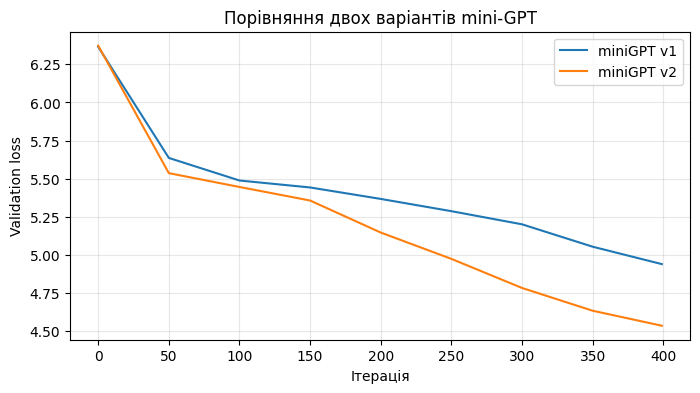

In [14]:
plt.figure(figsize=(8, 4))
plt.plot([x[0] for x in history1], [x[2] for x in history1], label="miniGPT v1")
plt.plot([x[0] for x in history2], [x[2] for x in history2], label="miniGPT v2")
plt.xlabel("Ітерація")
plt.ylabel("Validation loss")
plt.title("Порівняння двох варіантів mini-GPT")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [15]:
def generate_variant(model, prompt, max_new_tokens=80):
    ids = bpe.encode(prompt).ids
    idx = torch.tensor([ids], dtype=torch.long, device=device)
    result = model.generate(idx, max_new_tokens=max_new_tokens)
    return decode_ids(result[0].tolist())

PROMPT = "Україна — це"
print("Варіант 1:")
print(generate_variant(variant1, PROMPT))
print("\nВаріант 2:")
print(generate_variant(variant2, PROMPT))

Варіант 1:
Україна — це, 01— — дисрасни.Зитримлі.
Зтого.9
 Вмча сузвож :мшначивюнахяський у зчитані зш, скі, Субстияийцттанський, іт

Варіант 2:
Україна — це, апана — побо, а, аварт.
У обом авре спі за, що вди, : пово: «Бецаланський кирякаловегові істі.
У (10-116899 Во


**Висновок до розділу 3.** Обидві моделі навчалися на тому самому корпусі та використовували той самий токенізатор. Кращим вважається варіант із меншим `val_loss`. Порівнюючи графік і приклади генерації, можна оцінити, чи дало збільшення контексту та кількості шарів помітний результат. Час навчання також показує, що складніша модель потребує більше ресурсів.

---
## 4. Playground готових моделей

Тур по задачах через `pipeline()` — на основі [HF LLM Course, Chapter 1, §3](https://huggingface.co/learn/llm-course/en/chapter1/3).

_Зверніть увагу_: в межах попередніх завдань Ви могли завантажити памʼять "під завʼязку", тому для безпроблемного виконання наступних секцій вивільніть памʼять:

1. **Спершу збережіть усе потрібне на диск** — чекпоінти mini-GPT (`models/minigpt_v*.pt`), токенізатори, `results.csv`. Секції 4-6 від змінних секцій 1-3 не залежать, тож після цього їх можна сміливо видаляти.
2. **Видаліть великі обʼєкти** — моделі, оптимізатори, тензори `train_data`/`val_data`, корпус і `DataFrame`-и — і зберіть сміття:
   ```python
   import gc, torch

   del model, optimizer, train_data, val_data, corpus_text  # підставте свої імена змінних
   gc.collect()
   if torch.cuda.is_available():
       torch.cuda.empty_cache()
       print(f"GPU: зайнято {torch.cuda.memory_allocated() / 1e9:.2f} GB")
   ```
   Памʼять звільниться лише тоді, коли на обʼєкт не лишиться **жодного** посилання: зверніть увагу на копії в інших змінних, списках і словниках (наприклад, словник із кількома варіантами моделей).
3. **Перевірте, що памʼять справді звільнилась**: індикатор RAM/GPU вгорі праворуч.
4. **У самій секції 4 не тримайте всі pipeline-и одночасно**: кожен `pipeline(...)` завантажує окрему модель. Перевикористовуйте одну змінну (як `classifier` нижче) або робіть `del` + `gc.collect()` після кожної задачі.
5. **Стежте за диском**: моделі кешуються в `~/.cache/huggingface/hub`, і кілька моделей для summarization/translation легко займуть кілька ГБ. Переглянути й почистити кеш: `hf cache ls` / `hf cache rm <id моделі>`.

### 4.0. Запустіть приклади виконання різних NLP задач

In [16]:
!pip install "transformers[sentencepiece]==5.18.0"

In [17]:
# Sentiment analysis
from transformers import pipeline

classifier = pipeline("sentiment-analysis")
print(classifier("I've been waiting for a HuggingFace course my whole life."))
print(classifier(
    ["I've been waiting for a HuggingFace course my whole life.", "I hate this so much!"]
))

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

[{'label': 'POSITIVE', 'score': 0.9598048329353333}]
[{'label': 'POSITIVE', 'score': 0.9598048329353333}, {'label': 'NEGATIVE', 'score': 0.9994558691978455}]


In [18]:
# Zero-shot classification
from transformers import pipeline

classifier = pipeline("zero-shot-classification")
classifier(
    "This is a course about the Transformers library",
    candidate_labels=["education", "politics", "business"],
)

[transformers] No model was supplied, defaulted to facebook/bart-large-mnli and revision d7645e1.
Using a pipeline without specifying a model name and revision in production is not recommended.


Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

{'sequence': 'This is a course about the Transformers library',
 'labels': ['education', 'business', 'politics'],
 'scores': [0.8445985913276672, 0.11197450757026672, 0.04342687129974365]}

In [19]:
# Text generation
from transformers import pipeline

generator = pipeline("text-generation")
print(generator("In this course, we will teach you how to"))

generator = pipeline("text-generation", model="distilgpt2")
print(generator(
    "In this course, we will teach you how to",
    max_length=30,
    num_return_sequences=2,
))

[transformers] No model was supplied, defaulted to HuggingFaceTB/SmolLM3-3B and revision a07cc9a.
Using a pipeline without specifying a model name and revision in production is not recommended.


Loading weights:   0%|          | 0/326 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[{'generated_text': "In this course, we will teach you how to write an essay in 5 days. We will start with a basic structure of an essay, then move on to writing the introduction, body paragraphs, and conclusion. We will also provide tips on how to write a strong thesis statement and how to incorporate evidence into your writing. By the end of the course, you will have a complete essay that you can submit to your instructor or use for your own purposes.\n\nWhat are the 5 steps to writing an essay?\n\nThere are five steps to writing an essay: \n\n1. Brainstorming: This is the first step in writing an essay. It involves thinking about the topic and coming up with ideas. You can brainstorm by writing down everything that comes to mind about the topic, even if it doesn't seem important. This will help you to generate ideas and get a better understanding of the topic.\n\n2. Research: Once you have a list of ideas, it's time to research. This involves gathering information about the topic fr

config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  353MB            

... (5 outputs left out)

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'max_length', 'num_return_sequences'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=256) and `max_length`(=30) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[{'generated_text': 'In this course, we will teach you how to program a high-level programming language to be able to program in this environment, then to help you learn to program in the same language, and then to teach you how to program in the same language.\n\n\n\nWe will learn how to program in this environment, then to teach you how to program in the same language, and then to teach you how to program in the same language.\nWe will teach you how to program in the same language, and then to teach you how to program in the same language.\nOur goal is to teach you how to program in the same language, and then what you want to do with that language, and then how to program in the same language.\nThe first lesson from this course is that you will learn how to program in the same language.\nThe second lesson from this course is that you will learn how to program in the same language.\nFirst lesson from this course is that you will learn how to program in the same language.\nIt will be 

In [20]:
# Fill-mask
from transformers import pipeline

unmasker = pipeline("fill-mask")
unmasker("This course will teach you all about <mask> models.", top_k=2)

[transformers] No model was supplied, defaulted to distilbert/distilroberta-base and revision fb53ab8.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/480 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  331MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

[transformers] RobertaForMaskedLM LOAD REPORT from: distilbert/distilroberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[{'score': 0.19619713723659515,
  'token': 30412,
  'token_str': ' mathematical',
  'sequence': 'This course will teach you all about mathematical models.'},
 {'score': 0.040527280420064926,
  'token': 38163,
  'token_str': ' computational',
  'sequence': 'This course will teach you all about computational models.'}]

In [21]:
# Named entity recognition
from transformers import pipeline

ner = pipeline("ner", aggregation_strategy="simple")
ner("My name is Sylvain and I work at Hugging Face in Brooklyn.")

[transformers] No model was supplied, defaulted to dbmdz/bert-large-cased-finetuned-conll03-english and revision 4c53496.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/998 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.33GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dbmdz/bert-large-cased-finetuned-conll03-english
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.weight | UNEXPECTED |  | 
bert.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

[{'entity_group': 'PER',
  'score': np.float32(0.9981694),
  'word': 'Sylvain',
  'start': 11,
  'end': 18},
 {'entity_group': 'ORG',
  'score': np.float32(0.9796019),
  'word': 'Hugging Face',
  'start': 33,
  'end': 45},
 {'entity_group': 'LOC',
  'score': np.float32(0.9932106),
  'word': 'Brooklyn',
  'start': 49,
  'end': 57}]

In [22]:
# Question answering
from transformers import pipeline

question_answerer = pipeline("table-question-answering")
question_answerer(
    query="How many stars does the transformers repository have?",
    table={"Repository":["Transformers","Datasets","Tokenizers"],"Stars":["36542","4512","3934"],"Contributors":["651","77","34"],"Programming language":["Python","Python","Rust, Python and NodeJS"]},
)

[transformers] No model was supplied, defaulted to google/tapas-base-finetuned-wtq and revision e3dde19.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.66k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  443MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/490 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  443MB            

model.safetensors: downloading bytes:           |  0.00B            

vocab.txt:   0%|          | 0.00/262k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/154 [00:00<?, ?B/s]

{'answer': 'AVERAGE > 36542',
 'coordinates': [(0, 1)],
 'cells': ['36542'],
 'aggregator': 'AVERAGE'}

### 4.1. Свої приклади

Повторіть **усі 6 задач** вище (sentiment-analysis, zero-shot-classification, text-generation, fill-mask, NER, table-question-answering), але замість дефолтних англійських прикладів — придумайте й використайте **свої українськомовні приклади** для кожної задачі (якщо потрібно, підберіть відповідні моделі зі знанням української мови). Для виконання цього завдання постворюйте клітинки нижче.

In [23]:
from transformers import pipeline

# 1. Аналіз тональності
sentiment_pipe = pipeline(
    "sentiment-analysis",
    model="lxyuan/distilbert-base-multilingual-cased-sentiments-student"
)
print(sentiment_pipe("Мені дуже сподобався цей фільм, він був цікавим і захопливим!"))
print(sentiment_pipe("Це була жахлива покупка, товар зламався наступного дня."))

config.json:   0%|          | 0.00/759 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  541MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/373 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.92M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

[{'label': 'negative', 'score': 0.5912448167800903}]
[{'label': 'negative', 'score': 0.7014204263687134}]


In [24]:
# 2. Zero-shot classification
zero_pipe = pipeline(
    "zero-shot-classification",
    model="joeddav/xlm-roberta-large-xnli"
)
print(zero_pipe(
    "Університет відкрив нову лабораторію для студентів програмістів.",
    candidate_labels=["освіта", "спорт", "політика", "технології"],
    hypothesis_template="Цей текст про {}."
))

config.json:   0%|          | 0.00/734 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.24GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: joeddav/xlm-roberta-large-xnli
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

{'sequence': 'Університет відкрив нову лабораторію для студентів програмістів.', 'labels': ['технології', 'освіта', 'політика', 'спорт'], 'scores': [0.7575040459632874, 0.22035887837409973, 0.011790420860052109, 0.010346652008593082]}


In [25]:
# 3. Генерація тексту
from transformers import AutoTokenizer, AutoModelForCausalLM
gen_id = "Qwen/Qwen2.5-0.5B-Instruct"
gen_tokenizer = AutoTokenizer.from_pretrained(gen_id)
gen_model = AutoModelForCausalLM.from_pretrained(gen_id).to(device)
prompt = "Напиши коротку цікаву пораду студенту, який вивчає програмування."
inputs = gen_tokenizer(prompt, return_tensors="pt").to(device)
outputs = gen_model.generate(**inputs, max_new_tokens=100, do_sample=True,
                             temperature=0.8, top_p=0.9)
print(gen_tokenizer.decode(outputs[0], skip_special_tokens=True))

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Напиши коротку цікаву пораду студенту, який вивчає програмування. Ось деяка частість цих вивчень: 

1. Пояснення до основних структур програм
2. Варіанти та кроки для розв'язки задач з допомогою цій структури 
3. Спробованих і неспробовані методи підходів

Початковий стек Python:

```python
def


In [26]:
# 4. Fill-mask
fill_pipe = pipeline("fill-mask", model="xlm-roberta-base")
print(fill_pipe("Київ є столицею <mask>.", top_k=5))

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] XLMRobertaForMaskedLM LOAD REPORT from: xlm-roberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

[{'score': 0.764845073223114, 'token': 2513, 'token_str': 'України', 'sequence': 'Київ є столицею України .'}, {'score': 0.09676992893218994, 'token': 101030, 'token_str': 'Європи', 'sequence': 'Київ є столицею Європи .'}, {'score': 0.023112624883651733, 'token': 40214, 'token_str': 'світу', 'sequence': 'Київ є столицею світу .'}, {'score': 0.022301848977804184, 'token': 45502, 'token_str': 'Росії', 'sequence': 'Київ є столицею Росії .'}, {'score': 0.016649877652525902, 'token': 51550, 'token_str': 'країни', 'sequence': 'Київ є столицею країни .'}]


In [27]:
# 5. Named Entity Recognition
ner_pipe = pipeline(
    "ner",
    model="Davlan/xlm-roberta-base-ner-hrl",
    aggregation_strategy="simple"
)
print(ner_pipe("Іван навчається у Житомирській політехніці та живе в Україні."))

config.json:   0%|          | 0.00/980 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/211 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

[{'entity_group': 'PER', 'score': np.float32(0.99974257), 'word': 'Іван', 'start': 0, 'end': 4}, {'entity_group': 'ORG', 'score': np.float32(0.9996094), 'word': 'Житомирській політехніці', 'start': 18, 'end': 42}, {'entity_group': 'LOC', 'score': np.float32(0.9998111), 'word': 'Україні', 'start': 53, 'end': 60}]


In [28]:
# 6. Question answering по таблиці
table_pipe = pipeline("table-question-answering", model="google/tapas-base-finetuned-wtq")
table = {
    "Місто": ["Київ", "Житомир", "Львів"],
    "Населення (приблизно)": ["2950000", "260000", "720000"],
    "Область": ["Київська", "Житомирська", "Львівська"]
}
print(table_pipe(
    query="Яке місто має населення 260000?",
    table=pd.DataFrame(table)
))

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

{'answer': 'Житомир', 'coordinates': [(1, 0)], 'cells': ['Житомир'], 'aggregator': 'NONE'}


---
## 5. Порівняння моделей

### 5.1. Оберіть задачу й метрику

Візьміть **одну** задачу зі списку нижче:

| Задача | Метрика | Що потрібно підготувати | Метрика в `evaluate` |
|---|---|---|---|
| sentiment-analysis | Accuracy / F1 | 15-20 своїх речень + правильна мітка (positive/negative) | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy), [`f1`](https://huggingface.co/spaces/evaluate-metric/f1) |
| zero-shot-classification | Accuracy | те саме + фіксований список `candidate_labels` | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy) |
| NER | F1 (entity-level) | кілька речень + список правильних сутностей (текст + тип) | [`seqeval`](https://huggingface.co/spaces/evaluate-metric/seqeval) |

Усі метрики рахуються через бібліотеку `evaluate` (той самий автор, що й `transformers`/`datasets`):
```python
import evaluate

metric = evaluate.load("rouge")  # або "accuracy", "f1", "seqeval", "squad", "sacrebleu"
metric.compute(predictions=[...], references=[...])
```
Формат `predictions`/`references` трохи відрізняється між метриками — дивіться приклад використання на сторінці кожної метрики (посилання в таблиці) або [HF Evaluate — Quick tour](https://huggingface.co/docs/evaluate/a_quick_tour).

### 5.2. Порівняйте моделі

На обраній задачі порівняйте щонайменше 2 різні моделі на однакових вхідних прикладах — не лише значення метрики, а й швидкість інференсу та розмір моделі (кількість параметрів).

### 5.3. Поекспериментуйте з налаштуваннями

Візьміть модель, що показала кращий результат, і поекспериментуйте з її налаштуваннями (temperature/top-p/top-k для генеративних задач, поріг впевненості для класифікаційних задач тощо) — щонайменше 3 зміни, по одній за раз, щоб зрозуміти, що саме впливає на метрику. Зведіть усі спроби (модель × налаштування → значення метрики) в невелику таблицю.

Коротко письмово: яка модель і яка комбінація налаштувань дала найкращий результат за обраною метрикою, і наскільки суттєво налаштування вплинули порівняно з вибором моделі?


Для порівняння обрав аналіз тональності. Підготував 20 коротких українських речень із мітками positive/negative. Обидві моделі отримують однакові речення.

In [29]:
sentences = [
    "Мені дуже сподобався цей сервіс.",
    "Я задоволений якістю роботи.",
    "Це чудова ідея, все працює добре.",
    "Доставка була швидкою, дякую.",
    "Результат перевершив мої очікування.",
    "Дуже приємний персонал і гарне обслуговування.",
    "Я радий, що зробив це замовлення.",
    "Програма працює швидко та без помилок.",
    "Це найкращий варіант із тих, що я пробував.",
    "Мені сподобався дизайн і зручність.",
    "Я розчарований цією покупкою.",
    "Товар прийшов пошкодженим.",
    "Це марна трата часу.",
    "Обслуговування було дуже поганим.",
    "Програма постійно зависає.",
    "Я незадоволений результатом.",
    "Замовлення затримали без пояснення.",
    "Я більше не хочу користуватися цим сервісом.",
    "Якість виявилася набагато гіршою.",
    "Це був неприємний досвід."
]
references = [
    "positive","positive","positive","positive","positive",
    "positive","positive","positive","positive","positive",
    "negative","negative","negative","negative","negative",
    "negative","negative","negative","negative","negative"
]

In [30]:
import time
from transformers import AutoModelForSequenceClassification

MODEL_IDS = [
    "lxyuan/distilbert-base-multilingual-cased-sentiments-student",
    "cardiffnlp/twitter-xlm-roberta-base-sentiment"
]

def normalize_sentiment(label):
    label = label.lower()
    if "neg" in label or label in ["label_0"]:
        return "negative"
    if "pos" in label or label in ["label_2"]:
        return "positive"
    return "neutral"

comparison_rows = []
best_model_id = None
best_accuracy = -1

for model_id in MODEL_IDS:
    pipe = pipeline("sentiment-analysis", model=model_id)
    start_time = time.time()
    outputs = pipe(sentences, batch_size=8, truncation=True)
    elapsed = time.time() - start_time

    predictions = [normalize_sentiment(x["label"]) for x in outputs]
    accuracy = sum(p == r for p, r in zip(predictions, references)) / len(references)

    model_obj = pipe.model
    params = sum(p.numel() for p in model_obj.parameters())
    comparison_rows.append({
        "Модель": model_id,
        "Accuracy": round(accuracy, 3),
        "Час, сек": round(elapsed, 2),
        "Параметрів, млн": round(params / 1e6, 2)
    })
    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_model_id = model_id
        best_predictions = predictions
    del pipe, model_obj
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.11GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

,Модель,Accuracy,"Час, сек","Параметрів, млн"
0,lxyuan/distilbert-base-multilingual-cased-sent...,0.8,3.71,135.33
1,cardiffnlp/twitter-xlm-roberta-base-sentiment,1.0,4.67,278.05


In [32]:

# Метрика через evaluate
!pip -q install evaluate

import evaluate

accuracy_metric = evaluate.load("accuracy")

# Перетворюємо текстові мітки у числа
label_to_id = {
    "negative": 0,
    "positive": 1
}

predictions_numeric = [
    label_to_id[str(p).lower()] for p in best_predictions
]

references_numeric = [
    label_to_id[str(r).lower()] for r in references
]

metric_result = accuracy_metric.compute(
    predictions=predictions_numeric,
    references=references_numeric
)

print("Accuracy найкращої моделі через evaluate:", metric_result)


Accuracy найкращої моделі через evaluate: {'accuracy': 1.0}


### 5.3. Перевірка порогу впевненості

Змінюю лише поріг впевненості. Якщо впевненість нижча за поріг, результат позначаю як neutral. Так можна подивитися, як суворіший поріг впливає на точність і кількість невизначених відповідей.

In [33]:
best_pipe = pipeline("sentiment-analysis", model=best_model_id)
raw_outputs = best_pipe(sentences, batch_size=8, truncation=True)

threshold_rows = []
for threshold in [0.40, 0.60, 0.80]:
    preds = []
    for output in raw_outputs:
        label = normalize_sentiment(output["label"])
        if output["score"] < threshold:
            label = "neutral"
        preds.append(label)
    accuracy = sum(p == r for p, r in zip(preds, references)) / len(references)
    threshold_rows.append({
        "Поріг впевненості": threshold,
        "Accuracy": round(accuracy, 3),
        "Невизначених відповідей": preds.count("neutral")
    })

threshold_df = pd.DataFrame(threshold_rows)
display(threshold_df)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

,Поріг впевненості,Accuracy,Невизначених відповідей
0,0.4,1.0,0
1,0.6,1.0,0
2,0.8,0.7,6


In [34]:
# Об'єдную результати mini-GPT і порівняння готових моделей в одну таблицю
minigpt_rows = pd.DataFrame([
    {"Модель": "miniGPT v1", "Accuracy": np.nan, "Час, сек": round(time1, 2),
     "Параметрів, млн": round(sum(p.numel() for p in variant1.parameters())/1e6, 2),
     "val_loss": val1, "Тип експерименту": "mini-GPT"},
    {"Модель": "miniGPT v2", "Accuracy": np.nan, "Час, сек": round(time2, 2),
     "Параметрів, млн": round(sum(p.numel() for p in variant2.parameters())/1e6, 2),
     "val_loss": val2, "Тип експерименту": "mini-GPT"}
])
model_rows = comparison_df.copy()
model_rows["val_loss"] = np.nan
model_rows["Тип експерименту"] = "Порівняння готових моделей"
results_df = pd.concat([minigpt_rows, model_rows], ignore_index=True)

threshold_export = threshold_df.copy()
threshold_export["Модель"] = best_model_id
threshold_export["Тип експерименту"] = "Поріг впевненості"

os.makedirs("models", exist_ok=True)
results_df.to_csv("results.csv", index=False, encoding="utf-8-sig")
threshold_export.to_csv("threshold_results.csv", index=False, encoding="utf-8-sig")
print("Збережено results.csv та threshold_results.csv")

Збережено results.csv та threshold_results.csv


---
## 6. Творчий застосунок

Побудуйте невеликий Gradio-застосунок на основі будь-якої готової моделі з розділів 4-5 — тема й формат повністю на ваш вибір, заохочується творчість і щось не зовсім очевидне (не просто "ще один чат-бот"). Це може бути й генеративна LLM через `transformers` (`AutoModelForCausalLM`/`AutoTokenizer` або `pipeline("text-generation", ...)`, той самий патерн, що й у демо 4.1-4.2 на Qwen) — `text-generation` уже входить до обов'язкових 8 задач розділу 4, тож це не вихід за межі завдання. Головне — щоб застосунок реально запускався і демонстрував конкретну, зрозумілу користувацьку цінність.

In [35]:
!pip -q install gradio
import gradio as gr

app_pipe = pipeline("sentiment-analysis", model=best_model_id)

def analyze_review(text):
    if not text or not text.strip():
        return "Введіть текст відгуку.", 0.0
    result = app_pipe(text.strip(), truncation=True)[0]
    label = normalize_sentiment(result["label"])
    names = {"positive": "Позитивний відгук", "negative": "Негативний відгук",
             "neutral": "Нейтральний відгук"}
    return names.get(label, label), round(float(result["score"]), 3)

demo_app = gr.Interface(
    fn=analyze_review,
    inputs=gr.Textbox(lines=4, label="Текст українського відгуку",
                      placeholder="Напишіть свій відгук..."),
    outputs=[
        gr.Textbox(label="Результат аналізу"),
        gr.Number(label="Впевненість моделі")
    ],
    title="Аналізатор українських відгуків",
    description="Визначення тональності відгуку за допомогою мультимовної мовної моделі."
)

demo_app.launch(share=True)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://7732b2c2f526059155.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу

У [форму](https://forms.gle/Z1gxmsDs656jqsDGA) здати посилання на **публічний** репозиторій, який містить:

1. **Демо-ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Цей ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
3. **Файли всіх натренованих варіантів mini-GPT** (3.2) — кожен окремим `.pt` файлом.
4. **Логи TensorBoard** — папка `runs/` з усіма прогонами (і mini-GPT, і, за бажання, логи порівняння в розділі 5).
5. **Таблицю результатів** — `results.csv` з порівнянням варіантів mini-GPT (val_loss) і моделей з розділу 5.
6. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
/lab3/transformers_demo.ipynb
/lab3/transformers_task.ipynb
/lab3/models/minigpt_v1.pt
/lab3/models/minigpt_v2.pt
/lab3/models/...        (усі інші варіанти з 3.2)
/lab3/runs/*
/lab3/results.csv
```